**Varibale Transformation**

`Variable transformation technique is used to convert the numerical column into a normal distribution. If any numerical column is already following the normal distribution, that means 99.72% of the data is on the safe side. If any numerical column is not following the normal distribution curve, that means we will be having a lot of outliers. To overcome that, if any numerical column is not following the normal distribution, the variable transformation technique will convert it into a normal distribution.`

- `Log Transformation `
- `reciprocal Transformation`
- `square root Transformation`
- `exponential Transformation`
- `BoxCox Transformation`
- `Yeojohnson Transformation`

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/Titanic-Dataset.csv" , usecols=['Age' , 'Fare'])
df = df.dropna()
df

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
885,39.0,29.1250
886,27.0,13.0000
887,19.0,30.0000
889,26.0,30.0000


In [ ]:
def fun(df,var):
  plt.figure(figsize = (8,3))
  plt.subplot(1,2,1)
  plt.title("Normal Distribution")
  df[var].plot(kind = 'kde' , color = 'r')

  plt.subplot(1,2,2)
  sns.boxplot(x = df[var])

  plt.show()


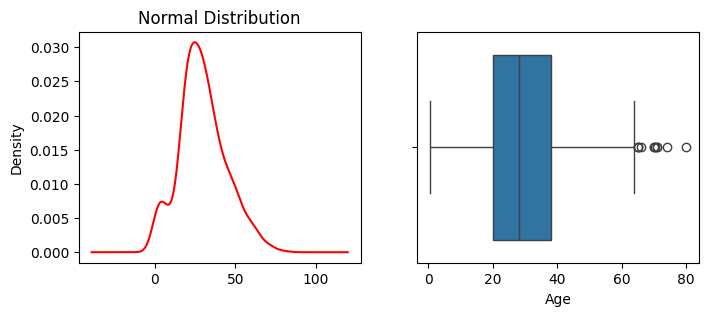

In [ ]:
fun(df,'Age')

In [ ]:
# log transformation

df['Age_log'] = np.log(df['Age'] + 1)

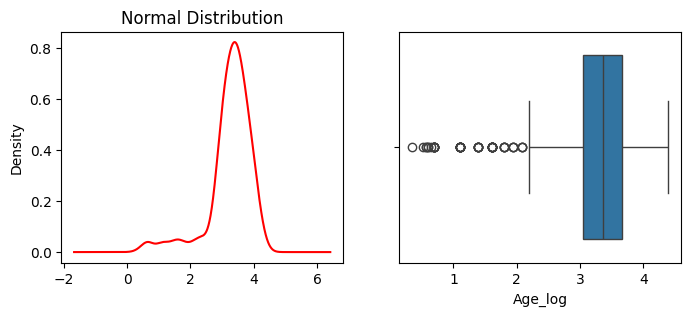

In [ ]:
fun(df,'Age_log')

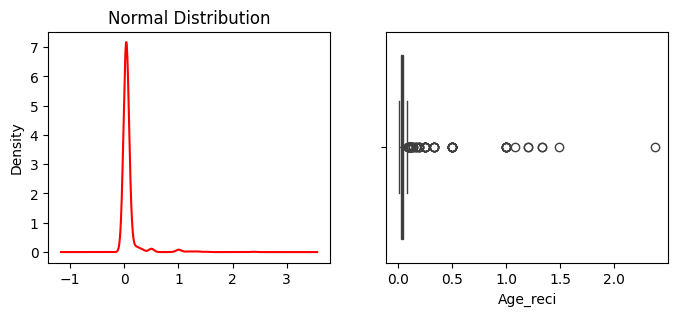

In [ ]:
# reciprocal
df['Age_reci'] = 1 / df['Age']

fun(df , 'Age_reci')

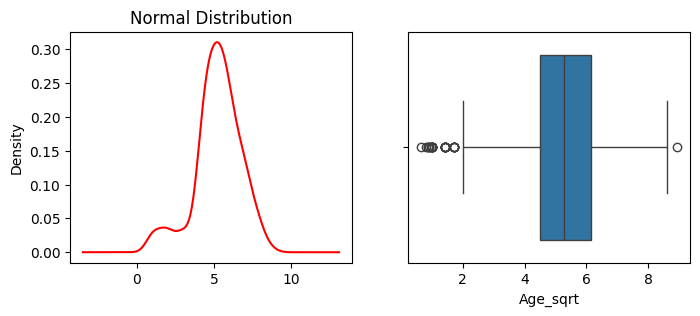

In [ ]:
# square root

df['Age_sqrt'] = np.sqrt(df['Age'])

fun(df , 'Age_sqrt')

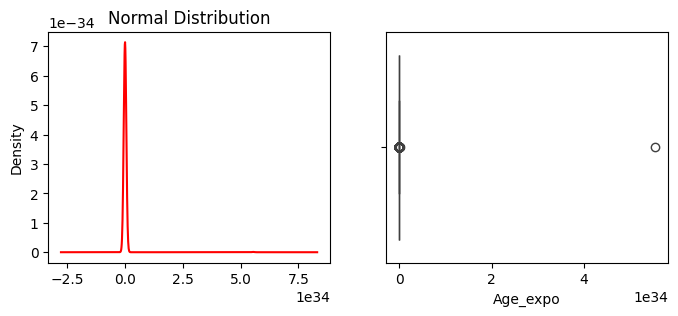

In [ ]:
# exponential
df['Age_expo'] = np.exp(df['Age'])
fun(df, 'Age_expo')

In [ ]:
from scipy.stats import boxcox

In [ ]:
# boxcox

df['Age_boxcox'] , lam_value = boxcox(df['Age'])

In [ ]:
lam_value

np.float64(0.762789049635355)

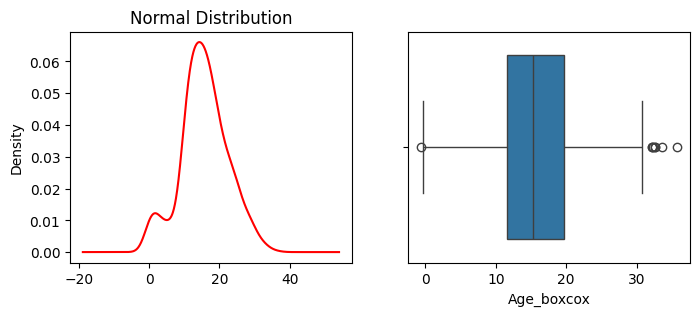

In [ ]:
fun(df , 'Age_boxcox')

In [ ]:
from scipy.stats import yeojohnson
df['Age_yeo'] , lam_value = yeojohnson(df['Age'])

In [ ]:
lam_value

np.float64(0.7582829698449309)

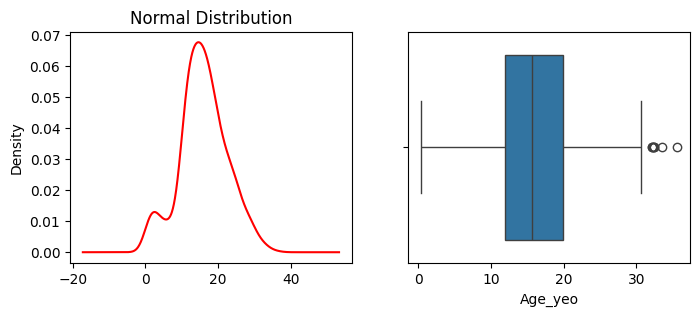

In [ ]:
fun(df , 'Age_yeo')

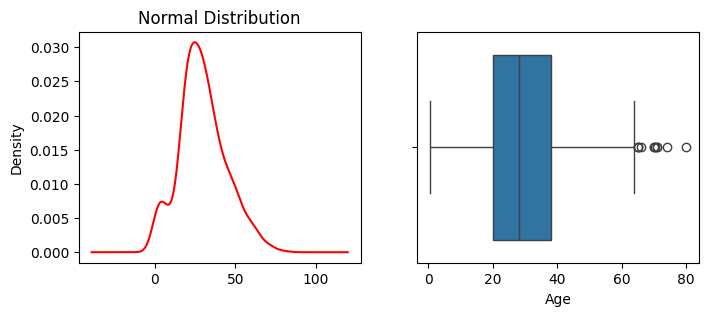

In [ ]:
fun(df , 'Age')

In [ ]:
df

,Age,Fare,Age_log,Age_reci,Age_sqrt,Age_expo,Age_boxcox,Age_yeo
0,22.0,7.2500,3.135494,0.045455,4.690416,3.584913e+09,12.543203,12.896128
1,38.0,71.2833,3.663562,0.026316,6.164414,3.185593e+16,19.709238,19.896371
2,26.0,7.9250,3.295837,0.038462,5.099020,1.957296e+11,14.426014,14.733908
3,35.0,53.1000,3.583519,0.028571,5.916080,1.586013e+15,18.431140,18.647016
4,35.0,8.0500,3.583519,0.028571,5.916080,1.586013e+15,18.431140,18.647016
...,...,...,...,...,...,...,...,...
885,39.0,29.1250,3.688879,0.025641,6.244998,8.659340e+16,20.129882,20.307595
886,27.0,13.0000,3.332205,0.037037,5.196152,5.320482e+11,14.885633,15.182753
887,19.0,30.0000,2.995732,0.052632,4.358899,1.784823e+08,11.077409,11.466727
889,26.0,30.0000,3.295837,0.038462,5.099020,1.957296e+11,14.426014,14.733908


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [17]:
df = pd.read_csv("/content/Titanic-Dataset.csv",usecols = ['Age','Fare'])
df = df.dropna()
df

,Age,Fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500
...,...,...
885,39.0,29.1250
886,27.0,13.0000
887,19.0,30.0000
889,26.0,30.0000


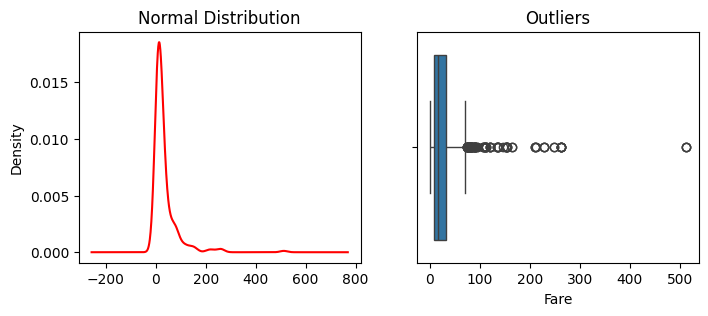

In [18]:
# Age column Normal distribution and outliers
plt.figure(figsize = (8,3))
plt.subplot(1,2,1)
plt.title("Normal Distribution")
df['Fare'].plot(kind = 'kde' , color = 'r')

plt.subplot(1,2,2)
plt.title("Outliers")
sns.boxplot(x = df['Fare'])

plt.show()

**Apply Yeojohnson on Age column**

In [19]:
from scipy.stats import yeojohnson
df['Fare_yeo'] , lam_value = yeojohnson(df['Fare'])


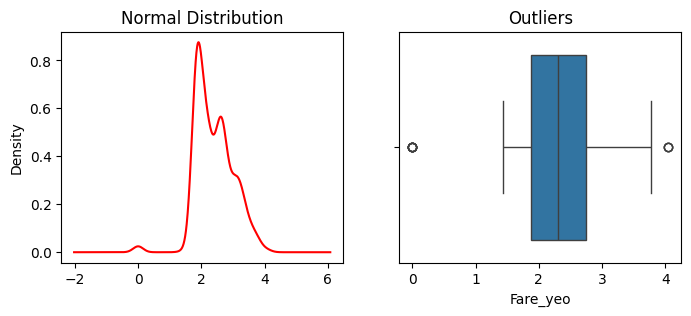

In [20]:
# Age column Normal distribution and outliers
plt.figure(figsize = (8,3))
plt.subplot(1,2,1)
plt.title("Normal Distribution")
df['Fare_yeo'].plot(kind = 'kde' , color = 'r')

plt.subplot(1,2,2)
plt.title("Outliers")
sns.boxplot(x = df['Fare_yeo'])

plt.show()

**Outliers Techniques**

- `Trimming `
- `capping `
- `5th and 95th Quantile `

In [21]:
# the values above upper limit and values below lower limit are outliers
# trimming : above upper limit values converted into upper limit and below lower limit values will be converted to
# lower limit


def calc(df ,var):
  iqr = df[var].quantile(0.75) - df[var].quantile(0.25)
  upper_limit = df[var].quantile(0.75) + (1.5 * iqr)
  lower_limit = df[var].quantile(0.25) - (1.5 * iqr)
  return lower_limit , upper_limit


lower , upper = calc(df,'Fare_yeo')
print(lower)
print(upper)

df['Fare_yeo_trimming'] = np.where(df['Fare_yeo'] > upper , upper ,
         np.where(df['Fare_yeo'] < lower , lower , df['Fare_yeo']))


df

0.5722729335577712
4.047955967124459


,Age,Fare,Fare_yeo,Fare_yeo_trimming
0,22.0,7.2500,1.808693,1.808693
1,38.0,71.2833,3.158178,3.158178
2,26.0,7.9250,1.865651,1.865651
3,35.0,53.1000,3.002405,3.002405
4,35.0,8.0500,1.875654,1.875654
...,...,...,...,...
885,39.0,29.1250,2.666205,2.666205
886,27.0,13.0000,2.179080,2.179080
887,19.0,30.0000,2.683342,2.683342
889,26.0,30.0000,2.683342,2.683342


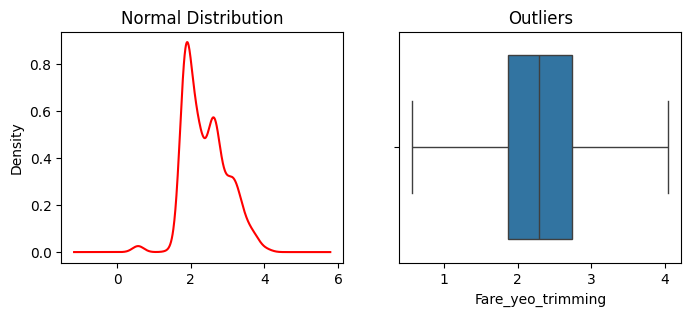

In [22]:
# Age column Normal distribution and outliers
plt.figure(figsize = (8,3))
plt.subplot(1,2,1)
plt.title("Normal Distribution")
df['Fare_yeo_trimming'].plot(kind = 'kde' , color = 'r')

plt.subplot(1,2,2)
plt.title("Outliers")
sns.boxplot(x = df['Fare_yeo_trimming'])

plt.show()

**capping**

In [23]:
def cal_2(df , var):
  upper = df[var].mean() + 3 * df[var].std()
  lower = df[var].mean() - 3 * df[var].std()
  return lower , upper



lower , upper  = cal_2(df , 'Fare_yeo')

df['Fare_yeo_capping'] = np.where(df['Fare_yeo'] > upper , upper ,
         np.where(df['Fare_yeo'] < lower , lower , df['Fare_yeo']))


df

,Age,Fare,Fare_yeo,Fare_yeo_trimming,Fare_yeo_capping
0,22.0,7.2500,1.808693,1.808693,1.808693
1,38.0,71.2833,3.158178,3.158178,3.158178
2,26.0,7.9250,1.865651,1.865651,1.865651
3,35.0,53.1000,3.002405,3.002405,3.002405
4,35.0,8.0500,1.875654,1.875654,1.875654
...,...,...,...,...,...
885,39.0,29.1250,2.666205,2.666205,2.666205
886,27.0,13.0000,2.179080,2.179080,2.179080
887,19.0,30.0000,2.683342,2.683342,2.683342
889,26.0,30.0000,2.683342,2.683342,2.683342


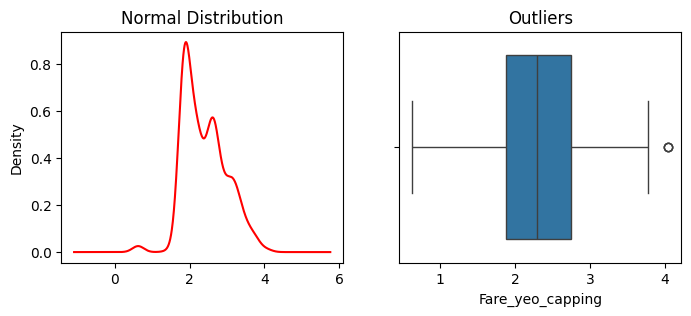

In [24]:
# Age column Normal distribution and outliers
plt.figure(figsize = (8,3))
plt.subplot(1,2,1)
plt.title("Normal Distribution")
df['Fare_yeo_capping'].plot(kind = 'kde' , color = 'r')

plt.subplot(1,2,2)
plt.title("Outliers")
sns.boxplot(x = df['Fare_yeo_capping'])

plt.show()

**5th and 95th Quantile**

In [25]:
def cal_3(df , var):
  upper = df[var].quantile(0.95)
  lower = df[var].quantile(0.05)
  return lower , upper



lower , upper  = cal_3(df , 'Fare_yeo')

df['Fare_yeo_5th_95th'] = np.where(df['Fare_yeo'] > upper , upper ,
         np.where(df['Fare_yeo'] < lower , lower , df['Fare_yeo']))


df

,Age,Fare,Fare_yeo,Fare_yeo_trimming,Fare_yeo_capping,Fare_yeo_5th_95th
0,22.0,7.2500,1.808693,1.808693,1.808693,1.808693
1,38.0,71.2833,3.158178,3.158178,3.158178,3.158178
2,26.0,7.9250,1.865651,1.865651,1.865651,1.865651
3,35.0,53.1000,3.002405,3.002405,3.002405,3.002405
4,35.0,8.0500,1.875654,1.875654,1.875654,1.875654
...,...,...,...,...,...,...
885,39.0,29.1250,2.666205,2.666205,2.666205,2.666205
886,27.0,13.0000,2.179080,2.179080,2.179080,2.179080
887,19.0,30.0000,2.683342,2.683342,2.683342,2.683342
889,26.0,30.0000,2.683342,2.683342,2.683342,2.683342


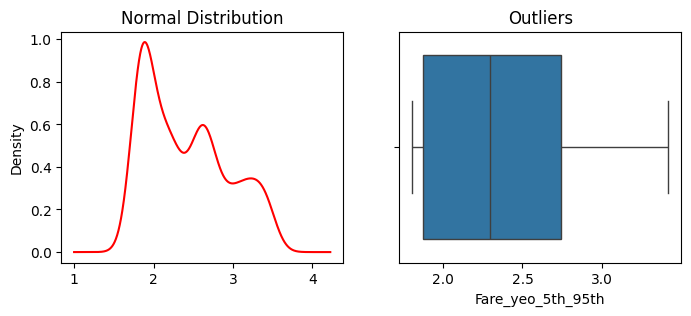

In [26]:
# Age column Normal distribution and outliers
plt.figure(figsize = (8,3))
plt.subplot(1,2,1)
plt.title("Normal Distribution")
df['Fare_yeo_5th_95th'].plot(kind = 'kde' , color = 'r')

plt.subplot(1,2,2)
plt.title("Outliers")
sns.boxplot(x = df['Fare_yeo_5th_95th'])

plt.show()